In [1]:
import numpy as np
import matplotlib.pyplot as plt
SEED = 5
rng = np.random.default_rng(SEED)
rng_step7 = rng.spawn(1)[0]

In [2]:
# Parameter
N_bits = 1000
p_error = 0.005
q = 0.7
num_runs = 200
# 30 log-spaced checkpoints from 10 to 10^5
checkpoints = np.unique(np.logspace(1, 5, 30).astype(int))

# Binomial from step 4
binomial_mean_theory = N_bits * p_error
binomial_var_theory = N_bits * p_error * (1 - p_error)

# Geometric from step 6
geometric_mean_theory = 1 / q
geometric_var_theory = (1 - q) / (q**2)

print("Binomial Distribution")
print("Theoretical Mean =", round(binomial_mean_theory, 6))
print("Theoretical Variance =", round(binomial_var_theory, 6))
print()
print("Geometric Distribution")
print("Theoretical Mean =", round(geometric_mean_theory, 6))
print("Theoretical Variance =", round(geometric_var_theory, 6))
print()
print("Number of checkpoints =", len(checkpoints))
print("Checkpoints:")
print(checkpoints)

Binomial Distribution
Theoretical Mean = 5.0
Theoretical Variance = 4.975

Geometric Distribution
Theoretical Mean = 1.428571
Theoretical Variance = 0.612245

Number of checkpoints = 30
Checkpoints:
[    10     13     18     25     35     48     67     92    126    174
    239    329    452    621    853   1172   1610   2212   3039   4175
   5736   7880  10826  14873  20433  28072  38566  52983  72789 100000]


In [9]:
# Run 200 Independent Experiments
binomial_running_means = np.zeros((num_runs, len(checkpoints)))

geometric_running_means = np.zeros((num_runs, len(checkpoints)))
for run in range(num_runs):
    binomial_total = 0.0
    geometric_total = 0.0
    previous_N = 0
    for j, N in enumerate(checkpoints):     
        block_size = N - previous_N # Number of new samples required
        binomial_samples = rng_step7.binomial(
            n=N_bits,
            p=p_error,
            size=block_size
        )
        binomial_total += np.sum(binomial_samples)
        binomial_running_means[run, j] = (
            binomial_total / N
        )
        geometric_samples = rng_step7.geometric(
            p=q,
            size=block_size
        )
        geometric_total += np.sum(geometric_samples)
        geometric_running_means[run, j] = (
            geometric_total / N
        )
        previous_N = N

print("Stored Binomial array shape:", binomial_running_means.shape)
print("Stored Geometric array shape:", geometric_running_means.shape)

Stored Binomial array shape: (200, 30)
Stored Geometric array shape: (200, 30)


In [4]:
# Average running mean 
binomial_average = np.mean(binomial_running_means, axis=0)
geometric_average = np.mean(geometric_running_means, axis=0)

# Use one standard deviation
binomial_spread = np.std(binomial_running_means, axis=0, ddof=1)
geometric_spread = np.std(geometric_running_means, axis=0, ddof=1)

In [5]:
# Find the checkpoint closest to N = 1000
match_index = np.argmin(np.abs(checkpoints - 1000))
N_match = checkpoints[match_index]

# spread at N approximately equal to 1000
binomial_scale = (binomial_spread[match_index] * np.sqrt(N_match))
geometric_scale = (geometric_spread[match_index] * np.sqrt(N_match))

binomial_envelope = (binomial_scale / np.sqrt(checkpoints))
geometric_envelope = (geometric_scale / np.sqrt(checkpoints))

print("1/sqrt(N) envelope matched at N =", N_match)

1/sqrt(N) envelope matched at N = 853


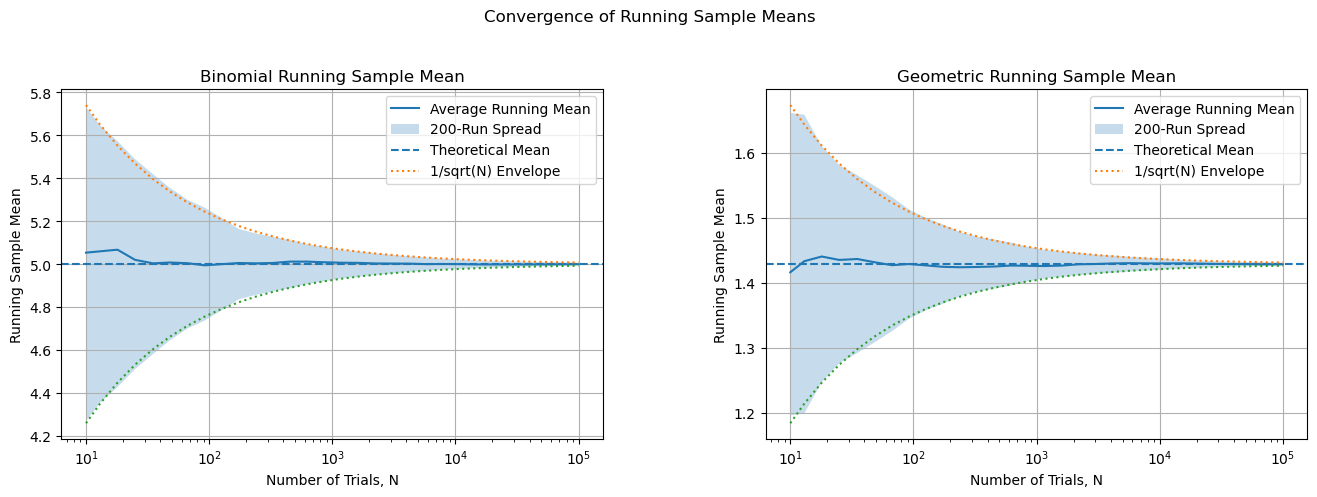

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1 - Binomial
ax[0].plot(checkpoints,
    binomial_average,
    label="Average Running Mean")
ax[0].fill_between(checkpoints,
    binomial_mean_theory - binomial_spread,
    binomial_mean_theory + binomial_spread,
    alpha=0.25, label="200-Run Spread")
ax[0].axhline(binomial_mean_theory, linestyle="--", label="Theoretical Mean")
ax[0].plot(checkpoints,
    binomial_mean_theory + binomial_envelope,
    linestyle=":", label="1/sqrt(N) Envelope")
ax[0].plot(checkpoints,
    binomial_mean_theory - binomial_envelope,
    linestyle=":")
ax[0].set_xscale("log")
ax[0].set_xlabel("Number of Trials, N")
ax[0].set_ylabel("Running Sample Mean")
ax[0].set_title("Binomial Running Sample Mean")
ax[0].grid(True)
ax[0].legend()

# Panel 2 - Geometric
ax[1].plot(checkpoints, geometric_average, label="Average Running Mean")
ax[1].fill_between(checkpoints,
    geometric_mean_theory - geometric_spread,
    geometric_mean_theory + geometric_spread,
    alpha=0.25, label="200-Run Spread")
ax[1].axhline(geometric_mean_theory, linestyle="--", label="Theoretical Mean")
ax[1].plot(checkpoints,
    geometric_mean_theory + geometric_envelope,
    linestyle=":", label="1/sqrt(N) Envelope")
ax[1].plot(checkpoints,
    geometric_mean_theory - geometric_envelope,
    linestyle=":")
ax[1].set_xscale("log")
ax[1].set_xlabel("Number of Trials, N")
ax[1].set_ylabel("Running Sample Mean")
ax[1].set_title("Geometric Running Sample Mean")
ax[1].grid(True)
ax[1].legend()

fig.suptitle("Convergence of Running Sample Means")
fig.subplots_adjust(
    left=0.08,
    right=0.97,
    bottom=0.12,
    top=0.82,
    wspace=0.30
)

plt.show()

The observed spread follows the $\frac{1}{\sqrt{N}}$ shape reasonably well. As N increases, the 200-run spread decreases at approximately the same rate as the scaled $\frac{1}{\sqrt{N}}$ envelope, with only small deviations due to finite simulation variability.



In [7]:
final_N = checkpoints[-1]

# Binomial comparison
binomial_final_estimate = binomial_average[-1]
binomial_difference = abs(binomial_final_estimate - binomial_mean_theory)
binomial_standard_error = (binomial_spread[-1]  / np.sqrt(num_runs))

# Geometric comparison
geometric_final_estimate = geometric_average[-1]
geometric_difference = abs(geometric_final_estimate - geometric_mean_theory)
geometric_standard_error = (geometric_spread[-1] / np.sqrt(num_runs))

print("THEORY VS SIMULATION COMPARISON")
print()

print("Binomial")
print("Theoretical Mean:", round(binomial_mean_theory, 6))
print("Simulation Mean:", round(binomial_final_estimate, 6))
print("Difference:", round(binomial_difference, 6))
print("Standard Error:", round(binomial_standard_error, 6))
print()

print("Geometric")
print("Theoretical Mean:", round(geometric_mean_theory, 6))
print("Simulation Mean:", round(geometric_final_estimate, 6))
print("Difference:", round(geometric_difference, 6))
print("Standard Error:", round(geometric_standard_error, 6))

THEORY VS SIMULATION COMPARISON

Binomial
Theoretical Mean: 5.0
Simulation Mean: 4.999835
Difference: 0.000165
Standard Error: 0.000443

Geometric
Theoretical Mean: 1.428571
Simulation Mean: 1.428332
Difference: 0.000239
Standard Error: 0.000168


In [8]:
# 1% CONVERGENCE
one_percent = 0.01 * binomial_mean_theory
C_values = (binomial_spread * np.sqrt(checkpoints))
C_est = np.median(C_values)

N_needed_est = (C_est / one_percent)**2

print("1% CONVERGENCE TEST")
print()
print("Theoretical Binomial Mean =", binomial_mean_theory)
print("1% of Theoretical Mean =", one_percent)
print("Estimated 1/sqrt(N) Constant =", round(C_est, 6))
print("Estimated Number of Trials =", round(N_needed_est))

1% CONVERGENCE TEST

Theoretical Binomial Mean = 5.0
1% of Theoretical Mean = 0.05
Estimated 1/sqrt(N) Constant = 2.324086
Estimated Number of Trials = 2161


### Theoretical Check for the 1 Percent Requirement

For the Binomial distribution: $\mu=5$ and $\sigma^2=4.975.$

The standard deviation of the sample mean is

$$
\sigma_{\bar{X}}
=
\frac{\sigma}{\sqrt{N}}.
$$

To make the spread smaller than 1 percent of the true mean,

$$
\frac{\sqrt{4.975}}{\sqrt{N}}
\leq
0.01(5)
$$

$$
\frac{\sqrt{4.975}}{\sqrt{N}}
\leq
0.05
$$

$$
\frac{4.975}{N}
\leq
0.0025
$$

$$
N
\geq
\frac{4.975}{0.0025}
$$

$$
N\geq1990
$$

Using the observed 200-run spread, the fitted convergence behavior is approximately

$$
\text{Spread}
=
\frac{2.324086}{\sqrt{N}}.
$$

To determine when the spread reaches 1 percent of the true mean,

$$
\frac{2.324086}{\sqrt{N}}
=
0.05.
$$

$$
N
=
\left(
\frac{2.324086}{0.05}
\right)^2
$$

$$
N\approx2161.
$$

Therefore, based on the width of the 200-run empirical band, approximately

$$
\boxed{2161\text{ trials}}
$$

are needed for the Binomial sample mean to be within 1 percent of the true mean.

The theoretical prediction is approximately 1990 trials, so the empirical result is reasonably close to the theoretical expectation.



